<a href="https://colab.research.google.com/github/Harsha192525108/MLA0204_HARSHA_192525108/blob/main/Practicals/practical-9/practical-9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LINEAR REGRESSION
MSE: 9558.259781101724
R2 Score: 0.8949808609738462

POLYNOMIAL REGRESSION
MSE: 292.13546351102445
R2 Score: 0.996790230067026


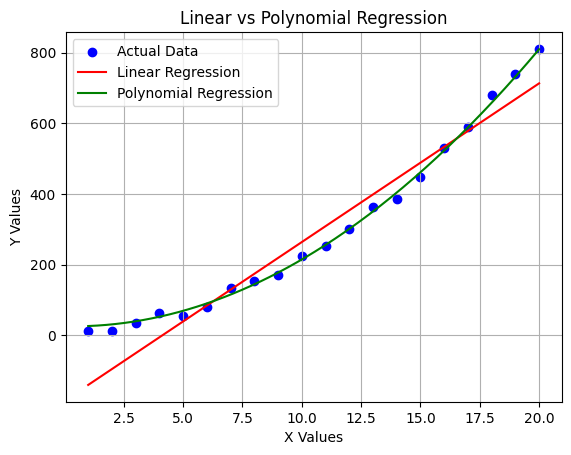

In [1]:

# Compare Linear Regression and Polynomial Regression

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# Step 1: Create a sample dataset
np.random.seed(42)

X = np.arange(1, 21).reshape(-1, 1)
y = 2 + 1.5 * X.ravel() + 2 * (X.ravel() ** 2)
y = y + np.random.normal(0, 15, 20)

# Step 2: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 3: Apply Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

# Step 4: Apply Polynomial Regression
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

poly_predictions = poly_model.predict(X_test_poly)

# Step 5: Compare model performance
print("LINEAR REGRESSION")
print("MSE:", mean_squared_error(y_test, linear_predictions))
print("R2 Score:", r2_score(y_test, linear_predictions))

print("\nPOLYNOMIAL REGRESSION")
print("MSE:", mean_squared_error(y_test, poly_predictions))
print("R2 Score:", r2_score(y_test, poly_predictions))

# Step 6: Plot both regression models
X_curve = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

linear_curve = linear_model.predict(X_curve)

poly_curve = poly_model.predict(
    poly.transform(X_curve)
)

plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X_curve, linear_curve, color="red",
         label="Linear Regression")
plt.plot(X_curve, poly_curve, color="green",
         label="Polynomial Regression")

plt.xlabel("X Values")
plt.ylabel("Y Values")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()
